In [11]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
from torchvision import transforms


In [4]:
image_dir = Path(r"/Volumes/Work/Learnings/DL_Computer_Vision/Data/concrete_segmentation/rgb")
mask_dir = Path(r"/Volumes/Work/Learnings/DL_Computer_Vision/Data/concrete_segmentation/BW")

In [9]:
image_names = sorted(os.listdir(image_dir))
mask_names = sorted(os.listdir(mask_dir))

In [38]:
img = Image.open(image_dir/image_names[0]).convert("RGB").resize((128,128))
img_mask = Image.open(mask_dir/mask_names[0]).convert("L").resize((128,128))

In [43]:
np.array(img).shape, np.array(img_mask).shape

((128, 128, 3), (128, 128))

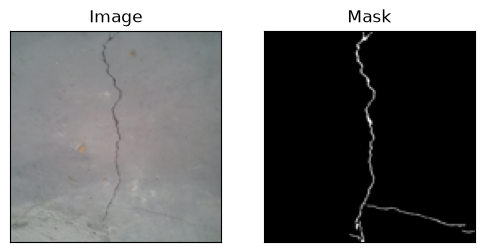

In [44]:
fig, axes =plt.subplots(1,2, figsize = (6,4))
axes[0].imshow(img),axes[0].set(title = 'Image', xticks = [], yticks = [])
axes[1].imshow(img_mask, cmap = 'gray'),axes[1].set(title = 'Mask', xticks = [], yticks = [])
plt.show()

In [53]:
from torch.utils.data import Dataset, DataLoader, random_split

In [45]:
# Simple dataset class
class SimpleDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transforms = None):
        super(SimpleDataset, self).__init__()
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_names = sorted(os.listdir(image_dir))
        self.mask_names = sorted(os.listdir(mask_dir))
        self.transforms = transforms

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        image_path = self.image_dir/self.image_names[idx]
        mask_path = self.mask_dir/self.mask_names[idx]

        image = Image.open(image_path).convert("RGB").resize((128,128))
        mask = Image.open(mask_path).convert("L").resize((128,128))

        image_tensor = transforms.ToTensor()(image)
        mask_tensor = transforms.ToTensor()(mask)

        return image_tensor, mask_tensor    

In [47]:
test_dataset = SimpleDataset(image_dir=image_dir, mask_dir= mask_dir)

In [48]:
print(len(test_dataset))

446


In [54]:
## Create train and validation dataset and then dataloader
train_dataset, val_dataset = random_split(test_dataset, [0.7, 0.3])

In [59]:
train_loader = DataLoader(train_dataset,
                          batch_size= 8,
                          shuffle= True)
val_loader = DataLoader(val_dataset,
                        batch_size= 8,
                        shuffle= False)

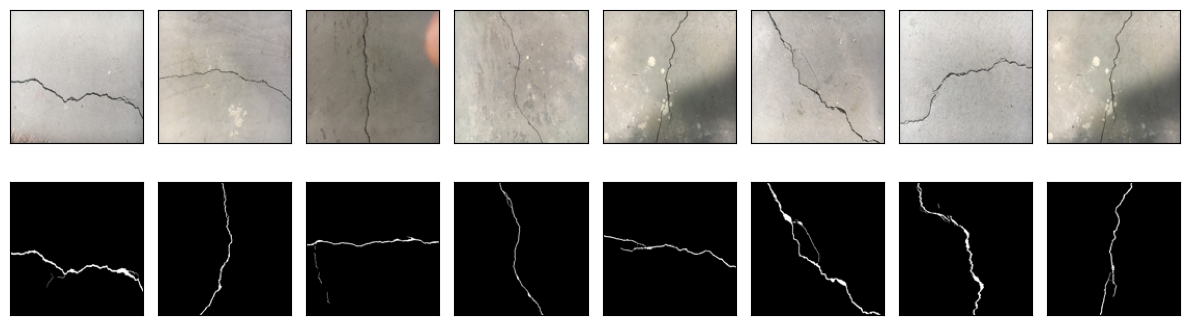

In [64]:
images, masks = next(iter(train_loader))

fig, axes = plt.subplots(2, len(images), figsize = (12,4))
axes = axes.flatten()
for i in range(len(images)):
    axes[i].imshow(images[i].permute(1,2,0))
    axes[i].set(title = "", xticks = [], yticks = [])

    axes[i+8].imshow(masks[i].squeeze(), cmap = 'gray')
    axes[i+8].set(title = "", xticks = [], yticks = [])

plt.tight_layout()
plt.show()